# Q5: Self-Consistency Results — Visualization

This notebook visualizes the effect of **self-consistency (majority voting)** on GSM8K accuracy for the Qwen2.5-0.5B model family, comparing different training pipelines and SC hyper-parameters (number of samples *N*, temperature *T*).

In [3]:
import json, os, re, glob
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook", font_scale=1.1)
plt.rcParams.update({"figure.dpi": 140, "savefig.bbox": "tight"})

OUTPUT_ROOT = "outputs/Qwen"
PLOT_DIR = "plots"
os.makedirs(PLOT_DIR, exist_ok=True)

## 1 — Load all results

In [4]:
def parse_results_txt(path):
    """Extract accuracy and SC parameters from a results.txt file."""
    with open(path) as f:
        text = f.read()
    acc_m = re.search(r'Overall Accuracy.*?(\d+\.\d+)%', text)
    accuracy = float(acc_m.group(1)) / 100 if acc_m else None
    n_m = re.search(r'N=(\d+)', text)
    t_m = re.search(r'T=([\d.]+)', text)
    n_samples = int(n_m.group(1)) if n_m else None
    temperature = float(t_m.group(1)) if t_m else None
    return accuracy, n_samples, temperature


def load_results_json(path):
    with open(path) as f:
        return json.load(f)


# --- Baseline (greedy) configs ---
baselines = {
    "Base\nZero-Shot":        "Qwen2.5-0.5B-base-zero-shot",
    "Instruct\nZero-Shot":    "Qwen2.5-0.5B-Instruct-zero-shot",
    "Base\nSFT":              "Qwen2.5-0.5B-base-sft",
    "Instruct\nSFT":          "Qwen2.5-0.5B-Instruct-sft",
    "Base\nSFT+GRPO":         "Qwen2.5-0.5B-base-sft_grpo",
    "Instruct\nSFT+GRPO":     "Qwen2.5-0.5B-Instruct-sft_grpo",
}

baseline_acc = {}
for label, dirname in baselines.items():
    txt = os.path.join(OUTPUT_ROOT, dirname, "results.txt")
    acc, _, _ = parse_results_txt(txt)
    baseline_acc[label] = acc

# --- SC configs (Instruct SFT+GRPO only) ---
sc_dirs = sorted(glob.glob(os.path.join(OUTPUT_ROOT, "*-sc*")))

sc_records = []
for d in sc_dirs:
    txt = os.path.join(d, "results.txt")
    if not os.path.exists(txt):
        continue
    acc, n, t = parse_results_txt(txt)
    sc_records.append({"dir": os.path.basename(d), "N": n, "T": t, "accuracy": acc})

sc_df = pd.DataFrame(sc_records)
print("Baselines:")
for k, v in baseline_acc.items():
    print(f"  {k.replace(chr(10), ' ')}: {v:.0%}")
print("\nSelf-consistency configs:")
sc_df

Baselines:
  Base Zero-Shot: 14%
  Instruct Zero-Shot: 14%
  Base SFT: 32%
  Instruct SFT: 34%
  Base SFT+GRPO: 30%
  Instruct SFT+GRPO: 32%

Self-consistency configs:


,dir,N,T,accuracy
0,Qwen2.5-0.5B-Instruct-sft_grpo-sc10-t3,10,0.3,0.39
1,Qwen2.5-0.5B-Instruct-sft_grpo-sc10-t5,10,0.5,0.43
2,Qwen2.5-0.5B-Instruct-sft_grpo-sc10-t7,10,0.7,0.42
3,Qwen2.5-0.5B-Instruct-sft_grpo-sc20-t3,20,0.3,0.35
4,Qwen2.5-0.5B-Instruct-sft_grpo-sc20-t5,20,0.5,0.48
5,Qwen2.5-0.5B-Instruct-sft_grpo-sc20-t7,20,0.7,0.46
6,Qwen2.5-0.5B-Instruct-sft_grpo-sc40-t3,40,0.5,0.45
7,Qwen2.5-0.5B-Instruct-sft_grpo-sc5-t5,5,0.5,0.37
8,Qwen2.5-0.5B-Instruct-sft_grpo-sc5-t7,5,0.7,0.34


## 2 — Training Pipeline Comparison (Greedy vs Best SC)

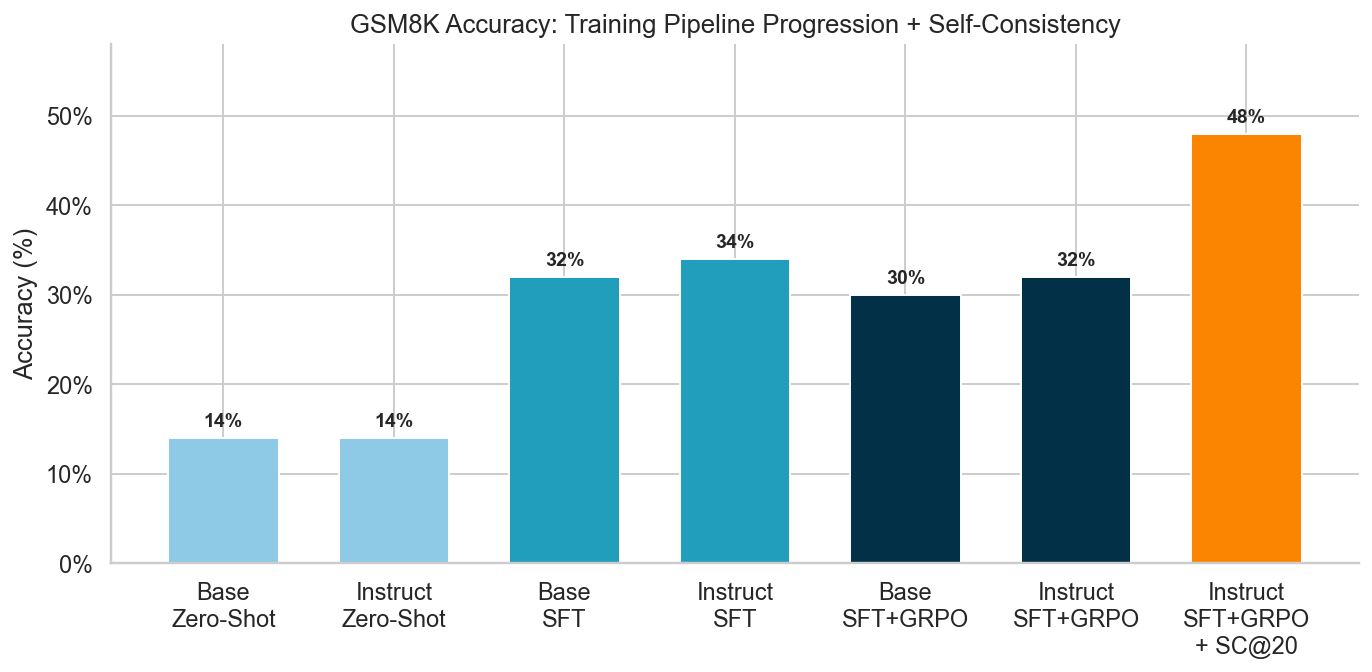

In [5]:
best_sc = sc_df.loc[sc_df["accuracy"].idxmax()]

labels = list(baseline_acc.keys()) + [f"Instruct\nSFT+GRPO\n+ SC@{int(best_sc.N)}"]
accs = list(baseline_acc.values()) + [best_sc.accuracy]

palette = ["#8ecae6"] * 2 + ["#219ebc"] * 2 + ["#023047"] * 2 + ["#fb8500"]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(labels, [a * 100 for a in accs], color=palette, edgecolor="white", width=0.65)
for bar, a in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8,
            f"{a:.0%}", ha="center", va="bottom", fontweight="bold", fontsize=10)

ax.set_ylabel("Accuracy (%)")
ax.set_title("GSM8K Accuracy: Training Pipeline Progression + Self-Consistency")
ax.set_ylim(0, max(accs) * 100 + 10)
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f%%'))
sns.despine()
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "pipeline_comparison.png"))
plt.show()

## 3 — Self-Consistency Heatmap: Accuracy by *N* × *T*

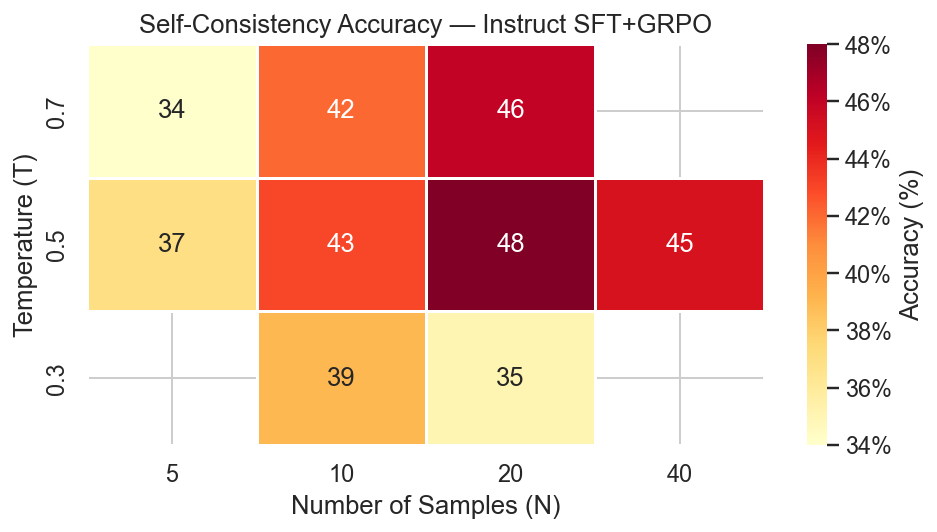

In [6]:
pivot = sc_df.pivot_table(index="T", columns="N", values="accuracy").sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(
    pivot * 100,
    annot=True, fmt=".0f", cmap="YlOrRd",
    linewidths=1.5, linecolor="white",
    cbar_kws={"label": "Accuracy (%)", "format": "%.0f%%"},
    ax=ax,
)
ax.set_xlabel("Number of Samples (N)")
ax.set_ylabel("Temperature (T)")
ax.set_title("Self-Consistency Accuracy — Instruct SFT+GRPO")
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "sc_heatmap.png"))
plt.show()

## 4 — Accuracy vs Number of Samples (by Temperature)

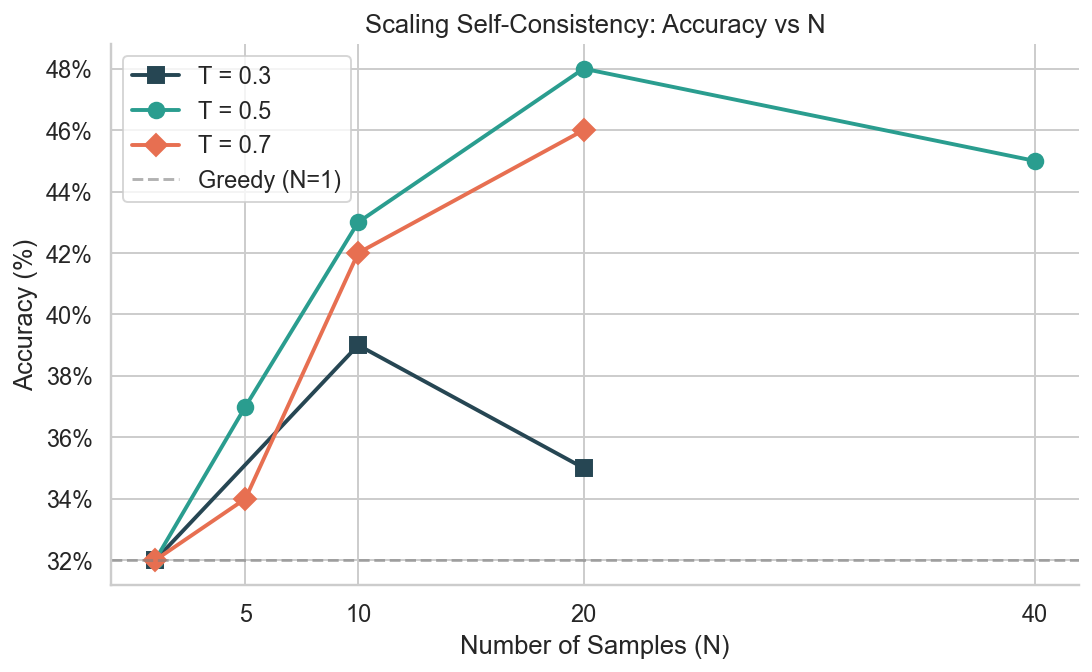

In [7]:
greedy_acc = baseline_acc["Instruct\nSFT+GRPO"]

fig, ax = plt.subplots(figsize=(8, 5))
markers = {0.3: "s", 0.5: "o", 0.7: "D"}
colors = {0.3: "#264653", 0.5: "#2a9d8f", 0.7: "#e76f51"}

for t, grp in sc_df.groupby("T"):
    grp_sorted = grp.sort_values("N")
    combined_n = np.concatenate([[1], grp_sorted["N"].values])
    combined_acc = np.concatenate([[greedy_acc * 100], grp_sorted["accuracy"].values * 100])
    ax.plot(combined_n, combined_acc,
            marker=markers.get(t, "o"), markersize=8, linewidth=2,
            color=colors.get(t, "gray"), label=f"T = {t}")

ax.axhline(greedy_acc * 100, color="gray", linestyle="--", alpha=0.6, label="Greedy (N=1)")
ax.set_xlabel("Number of Samples (N)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Scaling Self-Consistency: Accuracy vs N")
ax.set_xticks(sorted(sc_df["N"].unique()))
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f%%'))
ax.legend()
sns.despine()
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "sc_accuracy_vs_n.png"))
plt.show()

## 5 — Accuracy vs Temperature (by N)

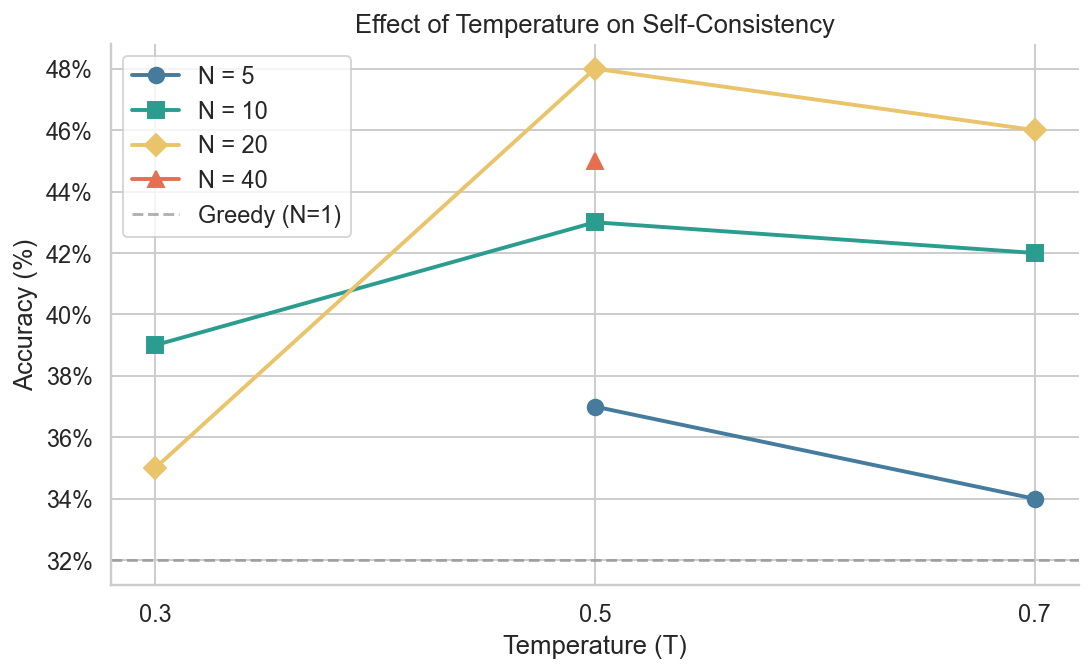

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
n_colors = {5: "#457b9d", 10: "#2a9d8f", 20: "#e9c46a", 40: "#e76f51"}
n_markers = {5: "o", 10: "s", 20: "D", 40: "^"}

for n, grp in sc_df.groupby("N"):
    grp_sorted = grp.sort_values("T")
    ax.plot(grp_sorted["T"], grp_sorted["accuracy"] * 100,
            marker=n_markers.get(n, "o"), markersize=8, linewidth=2,
            color=n_colors.get(n, "gray"), label=f"N = {n}")

ax.axhline(greedy_acc * 100, color="gray", linestyle="--", alpha=0.6, label="Greedy (N=1)")
ax.set_xlabel("Temperature (T)")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Effect of Temperature on Self-Consistency")
ax.set_xticks(sorted(sc_df["T"].unique()))
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f%%'))
ax.legend()
sns.despine()
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "sc_accuracy_vs_temp.png"))
plt.show()

## 6 — Per-Question Comparison: Greedy vs Best SC

How many questions are *rescued* by self-consistency (wrong under greedy, correct with SC), and how many are *lost* (correct under greedy, wrong with SC)?

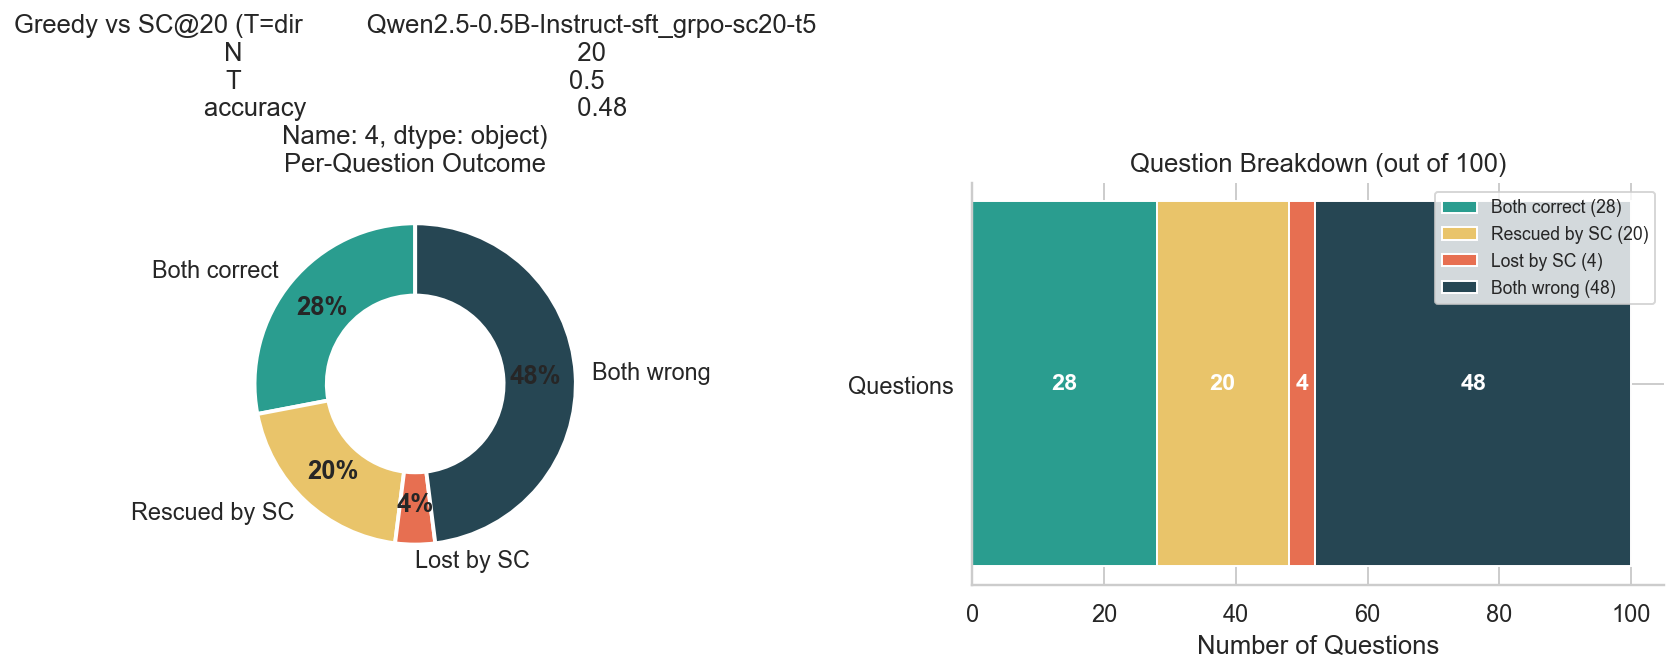

In [9]:
greedy_results = load_results_json(os.path.join(OUTPUT_ROOT, baselines["Instruct\nSFT+GRPO"], "results.json"))
best_sc_dir = sc_df.loc[sc_df["accuracy"].idxmax(), "dir"]
sc_best_results = load_results_json(os.path.join(OUTPUT_ROOT, best_sc_dir, "results.json"))

categories = {"Both correct": 0, "Rescued by SC": 0, "Lost by SC": 0, "Both wrong": 0}

for g, s in zip(greedy_results, sc_best_results):
    gc, sc_c = g["is_correct"], s["is_correct"]
    if gc and sc_c:
        categories["Both correct"] += 1
    elif not gc and sc_c:
        categories["Rescued by SC"] += 1
    elif gc and not sc_c:
        categories["Lost by SC"] += 1
    else:
        categories["Both wrong"] += 1

cat_colors = ["#2a9d8f", "#e9c46a", "#e76f51", "#264653"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Donut chart
wedges, texts, autotexts = axes[0].pie(
    categories.values(), labels=categories.keys(), autopct="%1.0f%%",
    colors=cat_colors, startangle=90, pctdistance=0.75,
    wedgeprops=dict(width=0.45, edgecolor="white", linewidth=2),
)
for t in autotexts:
    t.set_fontweight("bold")
axes[0].set_title(f"Greedy vs SC@{int(best_sc.N)} (T={best_sc.T})\nPer-Question Outcome")

# Stacked bar
cat_labels = list(categories.keys())
cat_vals = list(categories.values())
bottom = 0
for lbl, val, c in zip(cat_labels, cat_vals, cat_colors):
    axes[1].barh(["Questions"], [val], left=bottom, color=c, edgecolor="white",
                 height=0.5, label=f"{lbl} ({val})")
    axes[1].text(bottom + val / 2, 0, str(val), ha="center", va="center",
                 fontweight="bold", color="white", fontsize=12)
    bottom += val
axes[1].set_xlabel("Number of Questions")
axes[1].set_title("Question Breakdown (out of 100)")
axes[1].legend(loc="upper right", fontsize=9)
sns.despine(ax=axes[1])

fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "sc_per_question.png"))
plt.show()

## 7 — Answer Agreement & Diversity under SC

For each SC configuration, how much do the sampled reasoning paths **agree**? Higher agreement (lower entropy) means the model is more confident.

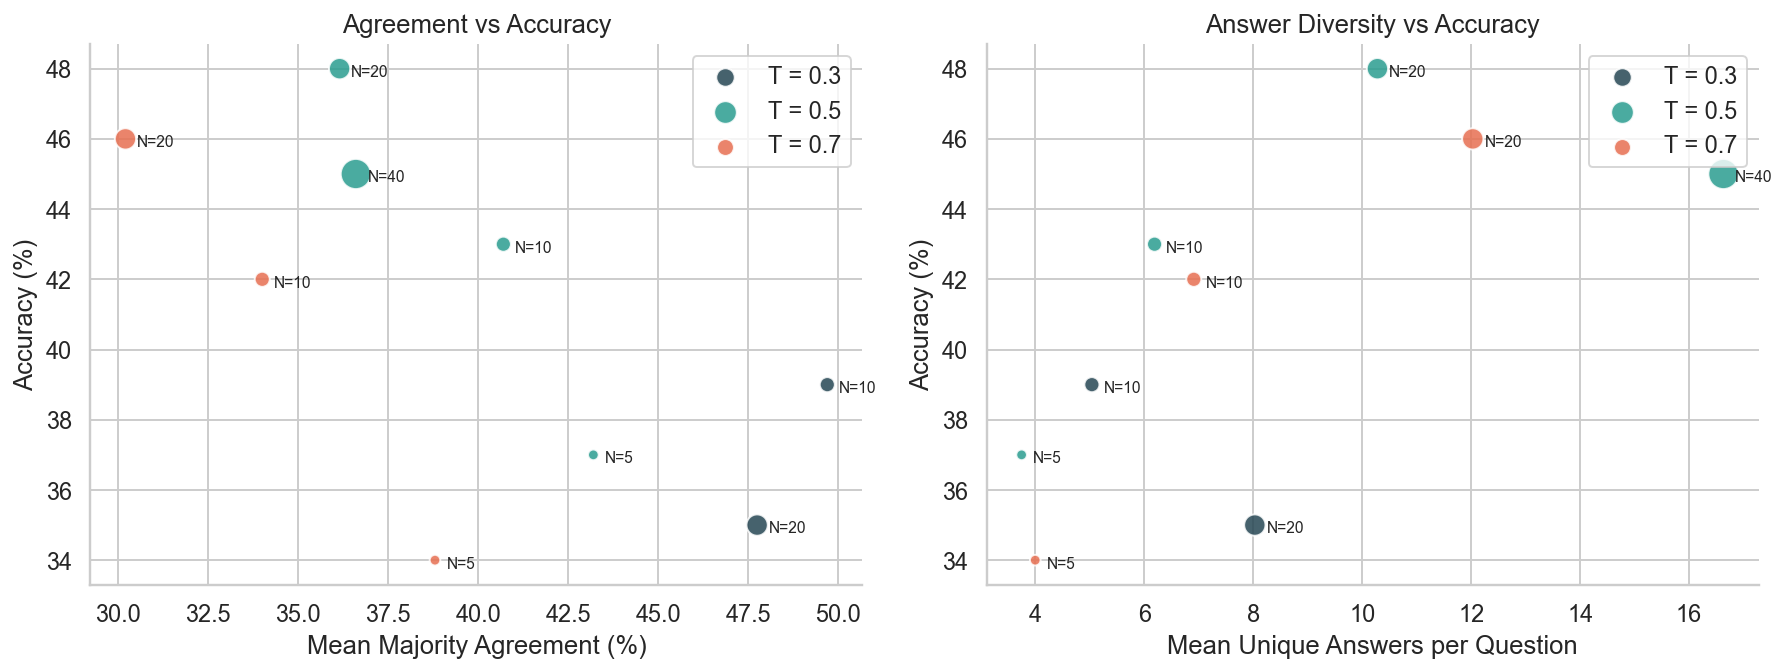

In [10]:
def agreement_rate(all_extracted):
    """Fraction of samples that match the majority vote."""
    if not all_extracted:
        return 0.0
    majority = Counter(all_extracted).most_common(1)[0][1]
    return majority / len(all_extracted)


def n_unique(all_extracted):
    return len(set(all_extracted)) if all_extracted else 0


rows = []
for _, row in sc_df.iterrows():
    results = load_results_json(os.path.join(OUTPUT_ROOT, row["dir"], "results.json"))
    agrees = [agreement_rate(r["all_extracted"]) for r in results]
    uniques = [n_unique(r["all_extracted"]) for r in results]
    rows.append({
        "config": f"SC@{row['N']}, T={row['T']}",
        "N": row["N"], "T": row["T"],
        "mean_agreement": np.mean(agrees),
        "mean_unique": np.mean(uniques),
        "accuracy": row["accuracy"],
    })

div_df = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Agreement vs Accuracy scatter
for t, grp in div_df.groupby("T"):
    axes[0].scatter(grp["mean_agreement"] * 100, grp["accuracy"] * 100,
                    s=grp["N"] * 6, alpha=0.85, label=f"T = {t}",
                    color=colors.get(t, "gray"), edgecolors="white", zorder=3)
    for _, r in grp.iterrows():
        axes[0].annotate(f"N={int(r['N'])}",
                         (r["mean_agreement"] * 100, r["accuracy"] * 100),
                         textcoords="offset points", xytext=(6, -4), fontsize=8)

axes[0].set_xlabel("Mean Majority Agreement (%)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Agreement vs Accuracy")
axes[0].legend()
sns.despine(ax=axes[0])

# Unique answers vs Accuracy scatter
for t, grp in div_df.groupby("T"):
    axes[1].scatter(grp["mean_unique"], grp["accuracy"] * 100,
                    s=grp["N"] * 6, alpha=0.85, label=f"T = {t}",
                    color=colors.get(t, "gray"), edgecolors="white", zorder=3)
    for _, r in grp.iterrows():
        axes[1].annotate(f"N={int(r['N'])}",
                         (r["mean_unique"], r["accuracy"] * 100),
                         textcoords="offset points", xytext=(6, -4), fontsize=8)

axes[1].set_xlabel("Mean Unique Answers per Question")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Answer Diversity vs Accuracy")
axes[1].legend()
sns.despine(ax=axes[1])

fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "sc_diversity.png"))
plt.show()

## 8 — Correct-Answer Rank in Sampled Paths

For questions the model gets *wrong* under greedy decoding, how often does the correct answer appear somewhere among the SC samples? This measures the **coverage** (oracle) potential.

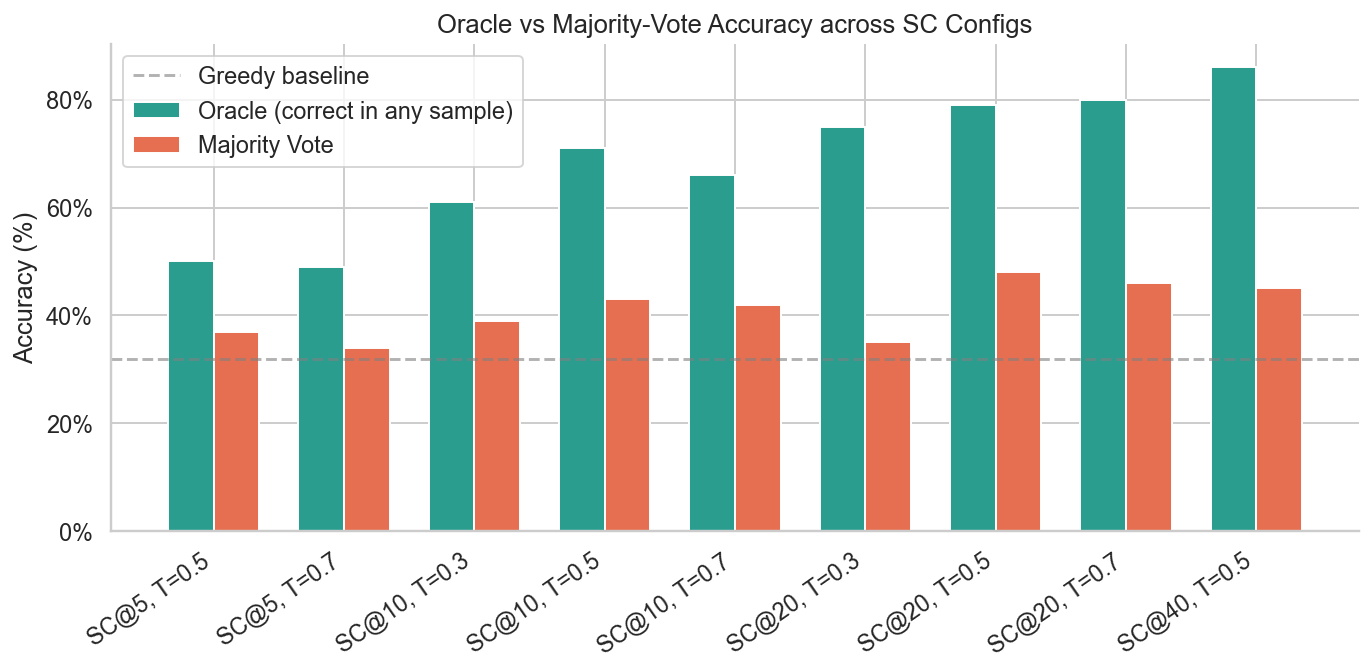

In [11]:
oracle_rows = []
for _, row in sc_df.iterrows():
    results = load_results_json(os.path.join(OUTPUT_ROOT, row["dir"], "results.json"))
    total = len(results)
    correct_in_samples = 0
    majority_correct = 0
    for r in results:
        if r["correct_answer"] in r.get("all_extracted", []):
            correct_in_samples += 1
        if r["is_correct"]:
            majority_correct += 1
    oracle_rows.append({
        "config": f"SC@{int(row['N'])}, T={row['T']}",
        "N": row["N"], "T": row["T"],
        "oracle_acc": correct_in_samples / total,
        "majority_acc": majority_correct / total,
    })

oracle_df = pd.DataFrame(oracle_rows).sort_values(["N", "T"])

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(oracle_df))
w = 0.35

ax.bar(x - w / 2, oracle_df["oracle_acc"] * 100, w,
       label="Oracle (correct in any sample)", color="#2a9d8f", edgecolor="white")
ax.bar(x + w / 2, oracle_df["majority_acc"] * 100, w,
       label="Majority Vote", color="#e76f51", edgecolor="white")

ax.axhline(greedy_acc * 100, color="gray", linestyle="--", alpha=0.6, label="Greedy baseline")

ax.set_xticks(x)
ax.set_xticklabels(oracle_df["config"], rotation=35, ha="right")
ax.set_ylabel("Accuracy (%)")
ax.set_title("Oracle vs Majority-Vote Accuracy across SC Configs")
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.0f%%'))
ax.legend()
sns.despine()
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, "sc_oracle_vs_majority.png"))
plt.show()

## 9 — Summary Table

In [12]:
summary_rows = []
for label, dirname in baselines.items():
    clean_label = label.replace("\n", " ")
    acc = baseline_acc[label]
    summary_rows.append({
        "Model / Config": clean_label,
        "N": 1, "T": "greedy",
        "Accuracy (%)": f"{acc:.0%}",
    })

for _, row in sc_df.sort_values("accuracy", ascending=False).iterrows():
    summary_rows.append({
        "Model / Config": f"Instruct SFT+GRPO + SC",
        "N": int(row["N"]), "T": row["T"],
        "Accuracy (%)": f"{row['accuracy']:.0%}",
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.style.set_caption("Full Results Summary").hide(axis="index")

Model / Config,N,T,Accuracy (%)
Base Zero-Shot,1,greedy,14%
Instruct Zero-Shot,1,greedy,14%
Base SFT,1,greedy,32%
Instruct SFT,1,greedy,34%
Base SFT+GRPO,1,greedy,30%
Instruct SFT+GRPO,1,greedy,32%
Instruct SFT+GRPO + SC,20,0.500000,48%
Instruct SFT+GRPO + SC,20,0.700000,46%
Instruct SFT+GRPO + SC,40,0.500000,45%
Instruct SFT+GRPO + SC,10,0.500000,43%
